# Conditioning: what the data determine, and what training can resolve

> **Repository:** [PINNs-RL-PDE](https://github.com/josegarciav/PINNs-RL-PDE) · **Docs:** [Identifiability and conditioning](https://josegarciav.github.io/PINNs-RL-PDE/theory/identifiability/) · [API: analysis](https://josegarciav.github.io/PINNs-RL-PDE/api/analysis/)

Two different conditionings appear in a PINN inverse problem and `pinnrl.analysis` keeps them apart:

1. **The conditioning of the inverse problem** (how well the sensors determine the parameters), measured by the Fisher information $F = J^\top J / \sigma^2$ of the sensitivities $J = \partial u / \partial\theta$. No solver improves it; only new sensors or a prior do. `pinnrl.analysis` computes $J$ exactly from a closed form (`exact_sensitivities`) or from the trained network by the implicit-function theorem (`surrogate_sensitivities`), which is what **K01** validates.
2. **The conditioning of training** (how hard the optimizer's job is), measured by the loss-Hessian spectrum and the tangent kernels of the loss terms (`loss_hessian_spectrum`, `tangent_kernel_spectrum`), which **K03** surveys across operators and architectures.

This notebook first shows the tools live on a small problem, then reviews the two experiments from their raw results.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments"
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def load(exp):
    """The raw runs of an experiment (every seed, every cell), or None if it has not been run."""
    path = EXP / exp / "results" / "runs.json"
    if not path.exists():
        display(Markdown(f"> **{exp} has no results yet.** Run `python experiments/{exp}/run.py` first."))
        return None
    return json.loads(path.read_text())


def figure(exp, png, script="plot.py"):
    """Re-render an experiment's figure from its raw results with its own plot script, then show it."""
    subprocess.run([sys.executable, str(EXP / exp / script)], check=True, capture_output=True)
    display(Image(filename=str(EXP / exp / "results" / png), width=1100))


def table(header, rows):
    """A Markdown table from a header list and rows of already formatted strings."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def med_iqr(values):
    v = np.asarray(values, dtype=float)
    q25, q75 = np.percentile(v, [25, 75])
    return f"{np.median(v):.3f} [{q25:.3f}, {q75:.3f}]"


def readme(exp, section="Conclusion"):
    """Show one section of the experiment's README, so the notebook and the folder say the same thing."""
    text = (EXP / exp / "README.md").read_text()
    body = text.split(f"## {section}")[1].split("\n## ")[0] if f"## {section}" in text else ""
    display(Markdown(f"**{section} (from `experiments/{exp}/README.md`)**\n" + body))

## The tools, live

A heat problem trained for a minute. `closed_form_bound` needs no training at all: it differentiates the catalogue's closed form. `surrogate_sensitivities` needs the trained network and the problem it was trained on; it makes the parameter trainable for the duration of the call, builds the Hessian blocks of the physics loss matrix-free and solves $H_{ww}\,\delta w = -H_{w\alpha}$ with MINRES.

In [2]:
import os, time
import torch
from pinnrl.analysis import closed_form_bound, exact_sensitivities, fisher_information, surrogate_sensitivities
from pinnrl.pdes.catalog import from_catalog

os.environ["TQDM_DISABLE"] = "1"
torch.manual_seed(0)
pde = from_catalog("heat")
trainer = pde.build_trainer(
    "feedforward", model={"hidden_dims": [32, 32, 32], "layer_norm": False},
    num_collocation_points=1024, batch_size=1024, num_boundary_points=256, num_initial_points=256,
    learning_rate=2e-3, scheduler_type="constant", early_stopping={"enabled": False},
    loss_weights={"residual": 1.0, "boundary": 10.0, "initial": 10.0},
)
t0 = time.time()
trainer.train_steps(num_steps=2000, resample_every=100)
print(f"trained in {time.time() - t0:.0f} s, relative L2 error {pde.validate(trainer.model)['l2_error']:.4f}")

trained in 12 s, relative L2 error 0.0078


surrogate sensitivities in 6.6 s: MINRES 300 iterations, residual 2.6e-03, damping 0.001
relative L2 difference to the closed form 0.020, correlation 0.9994


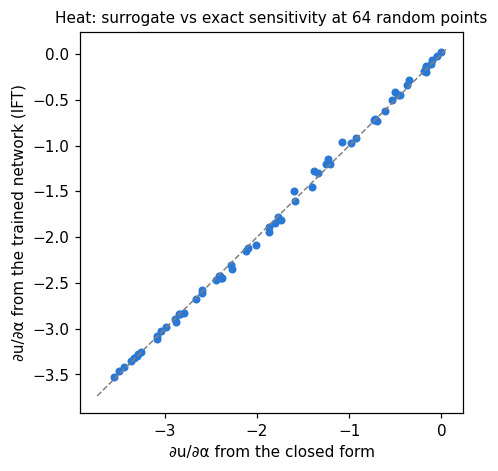

closed form  Cramér–Rao bound on std(α̂)/α at noise 0.05: 0.0299
surrogate    Cramér–Rao bound on std(α̂)/α at noise 0.05: 0.0298


In [3]:
torch.manual_seed(1)
x, t = torch.rand(64, 1), torch.rand(64, 1)
exact = exact_sensitivities(pde, ["alpha"], x, t)[:, 0, 0]
t0 = time.time()
sur = surrogate_sensitivities(pde, trainer.model, ["alpha"], x, t)
approx = sur.jacobian[:, 0, 0]
print(f"surrogate sensitivities in {time.time() - t0:.1f} s: MINRES {sur.cg_iterations[0]} iterations, residual {sur.cg_residuals[0]:.1e}, damping {sur.damping[0]:g}")
print(f"relative L2 difference to the closed form {float((approx - exact).norm() / exact.norm()):.3f}, correlation {float(torch.corrcoef(torch.stack([approx, exact]))[0, 1]):.4f}")
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(exact, approx, s=18, color="#2a78d6")
lim = [float(exact.min()) * 1.05, 0.05]
ax.plot(lim, lim, "--", color="gray", linewidth=1)
ax.set_xlabel("∂u/∂α from the closed form"); ax.set_ylabel("∂u/∂α from the trained network (IFT)")
ax.set_title("Heat: surrogate vs exact sensitivity at 64 random points", fontsize=10)
plt.show()
for name, J in [("closed form", exact), ("surrogate", approx)]:
    s = fisher_information(J[:, None], 0.05, ["alpha"])
    print(f"{name:<12} Cramér–Rao bound on std(α̂)/α at noise 0.05: {s.relative_std({'alpha': 0.1})['alpha']:.4f}")

The second tool: the extreme eigenvalues of the physics-loss Hessian at the trained weights (Lanczos with Hessian-vector products), and the tangent kernels of the residual, boundary and initial terms. The largest Hessian eigenvalue bounds the stable learning rate of gradient descent at $2/\lambda_{\max}$; a negative smallest Ritz value says the point is not a minimum; and a residual kernel whose trace dwarfs the boundary kernel's is the gradient-pathology diagnosis of Wang, Teng & Perdikaris (2021).

Hessian (Lanczos, 60 steps, 0.4 s): largest 618, smallest -0.3, condition number of the positive part 4.75e+04; stable GD learning rate < 3.23e-03


| term | trace of K | largest eigenvalue | condition number |
|---|---|---|---|
| residual | 928 | 620 | 8.59e+07 |
| boundary | 1.58e+03 | 998 | 1.28e+07 |
| initial | 1.33e+03 | 1.08e+03 | 1.31e+07 |

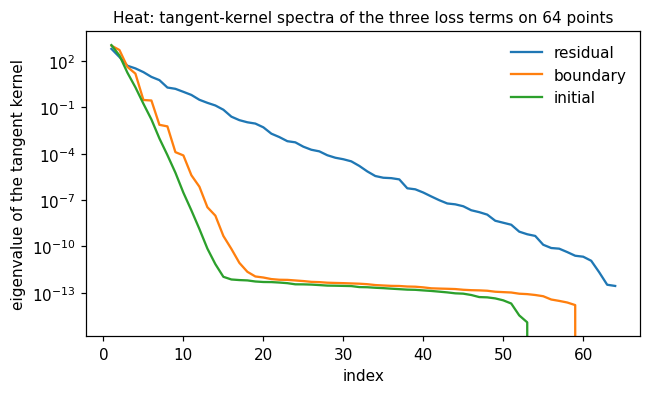

In [4]:
from pinnrl.analysis import loss_hessian_spectrum, tangent_kernel_spectrum

model = trainer.model
params = [p for p in model.parameters() if p.requires_grad]
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(0)
    xc, tc = pde.generate_collocation_points(1024)

def physics_loss():
    losses = pde.compute_loss(model, xc, tc)
    return losses["residual"] + 10 * losses["boundary"] + 10 * losses["initial"]

t0 = time.time()
hess = loss_hessian_spectrum(physics_loss, params, iterations=60)
print(f"Hessian (Lanczos, {hess.iterations} steps, {time.time() - t0:.1f} s): largest {hess.largest:.3g}, smallest {hess.smallest:.3g}, "
      f"condition number of the positive part {hess.condition_number():.3g}; stable GD learning rate < {2 / hess.largest:.2e}")

n = 64
xi, ti = torch.rand(n, 1), torch.rand(n, 1)
xb = torch.where(torch.rand(n, 1) < 0.5, 0.0, 1.0)
x0 = torch.rand(n, 1)
kernels = {
    "residual": tangent_kernel_spectrum(model, lambda m: pde.compute_residual(m, xi, ti)),
    "boundary": tangent_kernel_spectrum(model, lambda m: m(torch.cat([xb, ti], 1))),
    "initial": tangent_kernel_spectrum(model, lambda m: m(torch.cat([x0, torch.zeros(n, 1)], 1))),
}
table(["term", "trace of K", "largest eigenvalue", "condition number"],
      [[k, f"{v.trace:.3g}", f"{float(v.eigenvalues[0]):.3g}", f"{v.condition_number(1e-8 * float(v.eigenvalues[0])):.3g}"] for k, v in kernels.items()])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for k, v in kernels.items():
    ax.plot(np.arange(1, n + 1), v.eigenvalues.numpy(), label=k)
ax.set_yscale("log"); ax.set_xlabel("index"); ax.set_ylabel("eigenvalue of the tangent kernel"); ax.legend(frameon=False)
ax.set_title("Heat: tangent-kernel spectra of the three loss terms on 64 points", fontsize=10)
plt.show()

## K01: Fisher information from the trained surrogate, checked against the exact layer

**Question.** Which parameter combinations do the sensors determine, and can the trained network tell us without a closed form?

**Setup.** Three problems, three seeds. Heat ($\alpha$): forward training, 5,000 steps; the surrogate Jacobian on the F01 random layouts and the F05 probe layouts against the closed form $-\pi^2 t\, u$. KdV two-parameter ($\alpha, \beta$): data-augmented training (the soliton collapses without data), 8,000 steps; the 2 × 2 Fisher matrix against the symbolic sensitivities. Burgers ($\log\nu$): data-augmented training, 10,000 steps; against central differences of the Cole–Hopf reference. Noise 0.05 throughout.

In [5]:
runs = load("K01_fisher_information")
if runs:
    rows = []
    for rec in runs:
        for c in rec["cells"]:
            ex, su = c["exact"]["rel_std"], c["surrogate"]["rel_std"]
            names = list(ex)
            bound = " / ".join(f"{ex[k]:.3f}" for k in names)
            sbound = " / ".join(f"{su[k]:.3f}" for k in names)
            ratio = " / ".join(f"{su[k] / ex[k]:.2f}" for k in names)
            corr = f"{c['exact']['correlation'][0][1]:+.2f} / {c['surrogate']['correlation'][0][1]:+.2f}" if len(names) == 2 else "–"
            rows.append([rec["problem"], rec["seed"], f"{rec['l2_error']:.3f}", c["layout"], f"{c['jacobian_rel_error']:.3f}", bound, sbound, ratio, corr, f"{c['cg_residual']:.1e}"])
    table(["problem", "seed", "rel. L2 of u", "layout", "‖J_sur − J_ref‖ / ‖J_ref‖", "bound (ref)", "bound (surrogate)", "ratio", "correlation ref / sur", "solve residual"], rows)

| problem | seed | rel. L2 of u | layout | ‖J_sur − J_ref‖ / ‖J_ref‖ | bound (ref) | bound (surrogate) | ratio | correlation ref / sur | solve residual |
|---|---|---|---|---|---|---|---|---|---|
| heat | 0 | 0.038 | random_20 | 0.041 | 0.053 | 0.054 | 1.02 | – | 7.8e-03 |
| heat | 0 | 0.038 | random_50 | 0.057 | 0.037 | 0.038 | 1.04 | – | 7.8e-03 |
| heat | 0 | 0.038 | random_200 | 0.053 | 0.017 | 0.017 | 1.03 | – | 7.8e-03 |
| heat | 0 | 0.038 | random_1000 | 0.056 | 0.008 | 0.008 | 1.03 | – | 7.8e-03 |
| heat | 0 | 0.038 | sensors_1 | 0.032 | 0.012 | 0.013 | 1.03 | – | 7.8e-03 |
| heat | 0 | 0.038 | sensors_2 | 0.040 | 0.014 | 0.015 | 1.03 | – | 7.8e-03 |
| heat | 0 | 0.038 | sensors_4 | 0.047 | 0.016 | 0.016 | 1.03 | – | 7.8e-03 |
| heat | 0 | 0.038 | sensors_8 | 0.050 | 0.017 | 0.017 | 1.03 | – | 7.8e-03 |
| kdv_two_parameter | 0 | 0.006 | random_50 | 0.039 | 0.056 / 0.189 | 0.057 / 0.192 | 1.02 / 1.02 | +0.61 / +0.62 | 1.2e-04 |
| kdv_two_parameter | 0 | 0.006 | random_200 | 0.037 | 0.026 / 0.071 | 0.026 / 0.072 | 1.02 / 1.02 | +0.54 / +0.55 | 1.2e-04 |
| kdv_two_parameter | 0 | 0.006 | random_1000 | 0.037 | 0.014 / 0.034 | 0.015 / 0.035 | 1.02 / 1.01 | +0.64 / +0.64 | 1.2e-04 |
| burgers_log_nu | 0 | 0.028 | random_20 | 1.342 | 0.114 | 0.137 | 1.20 | – | 5.0e-03 |
| burgers_log_nu | 0 | 0.028 | random_50 | 1.808 | 0.123 | 0.077 | 0.62 | – | 5.0e-03 |
| burgers_log_nu | 0 | 0.028 | random_200 | 6.709 | 0.239 | 0.040 | 0.17 | – | 5.0e-03 |
| burgers_log_nu | 0 | 0.028 | random_1000 | 2.615 | 0.041 | 0.017 | 0.42 | – | 5.0e-03 |
| heat | 1 | 0.009 | random_20 | 0.018 | 0.048 | 0.049 | 1.01 | – | 2.6e-03 |
| heat | 1 | 0.009 | random_50 | 0.022 | 0.033 | 0.034 | 1.01 | – | 2.6e-03 |
| heat | 1 | 0.009 | random_200 | 0.025 | 0.018 | 0.018 | 1.02 | – | 2.6e-03 |
| heat | 1 | 0.009 | random_1000 | 0.025 | 0.008 | 0.008 | 1.02 | – | 2.6e-03 |
| heat | 1 | 0.009 | sensors_1 | 0.018 | 0.012 | 0.013 | 1.02 | – | 2.6e-03 |
| heat | 1 | 0.009 | sensors_2 | 0.019 | 0.014 | 0.015 | 1.02 | – | 2.6e-03 |
| heat | 1 | 0.009 | sensors_4 | 0.021 | 0.016 | 0.016 | 1.02 | – | 2.6e-03 |
| heat | 1 | 0.009 | sensors_8 | 0.023 | 0.017 | 0.017 | 1.02 | – | 2.6e-03 |
| kdv_two_parameter | 1 | 0.007 | random_50 | 0.051 | 0.063 / 0.163 | 0.064 / 0.167 | 1.02 / 1.02 | +0.68 / +0.69 | 1.6e-04 |
| kdv_two_parameter | 1 | 0.007 | random_200 | 0.053 | 0.032 / 0.081 | 0.033 / 0.082 | 1.02 / 1.01 | +0.65 / +0.66 | 1.6e-04 |
| kdv_two_parameter | 1 | 0.007 | random_1000 | 0.050 | 0.014 / 0.035 | 0.014 / 0.035 | 1.02 / 1.01 | +0.65 / +0.66 | 1.6e-04 |
| burgers_log_nu | 1 | 0.035 | random_20 | 24.176 | 4.434 | 0.189 | 0.04 | – | 6.9e-03 |
| burgers_log_nu | 1 | 0.035 | random_50 | 7.438 | 1.054 | 0.152 | 0.14 | – | 6.9e-03 |
| burgers_log_nu | 1 | 0.035 | random_200 | 3.996 | 0.111 | 0.034 | 0.30 | – | 6.9e-03 |
| burgers_log_nu | 1 | 0.035 | random_1000 | 3.219 | 0.055 | 0.018 | 0.32 | – | 6.9e-03 |
| heat | 2 | 0.026 | random_20 | 0.042 | 0.052 | 0.054 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | random_50 | 0.040 | 0.034 | 0.035 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | random_200 | 0.045 | 0.018 | 0.019 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | random_1000 | 0.044 | 0.008 | 0.008 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | sensors_1 | 0.025 | 0.012 | 0.013 | 1.02 | – | 5.0e-03 |
| heat | 2 | 0.026 | sensors_2 | 0.034 | 0.014 | 0.015 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | sensors_4 | 0.040 | 0.016 | 0.016 | 1.03 | – | 5.0e-03 |
| heat | 2 | 0.026 | sensors_8 | 0.042 | 0.017 | 0.017 | 1.03 | – | 5.0e-03 |
| kdv_two_parameter | 2 | 0.005 | random_50 | 0.036 | 0.049 / 0.117 | 0.050 / 0.118 | 1.03 / 1.01 | +0.65 / +0.66 | 1.6e-04 |
| kdv_two_parameter | 2 | 0.005 | random_200 | 0.038 | 0.030 / 0.075 | 0.031 / 0.077 | 1.03 / 1.02 | +0.57 / +0.59 | 1.6e-04 |
| kdv_two_parameter | 2 | 0.005 | random_1000 | 0.039 | 0.013 / 0.032 | 0.014 / 0.033 | 1.03 / 1.01 | +0.62 / +0.63 | 1.6e-04 |

/var/folders/yx/b_pyg98x1dj97pbflpck32d80000gn/T/ipykernel_84241/1691999380.py:11: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
/var/folders/yx/b_pyg98x1dj97pbflpck32d80000gn/T/ipykernel_84241/1691999380.py:11: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)


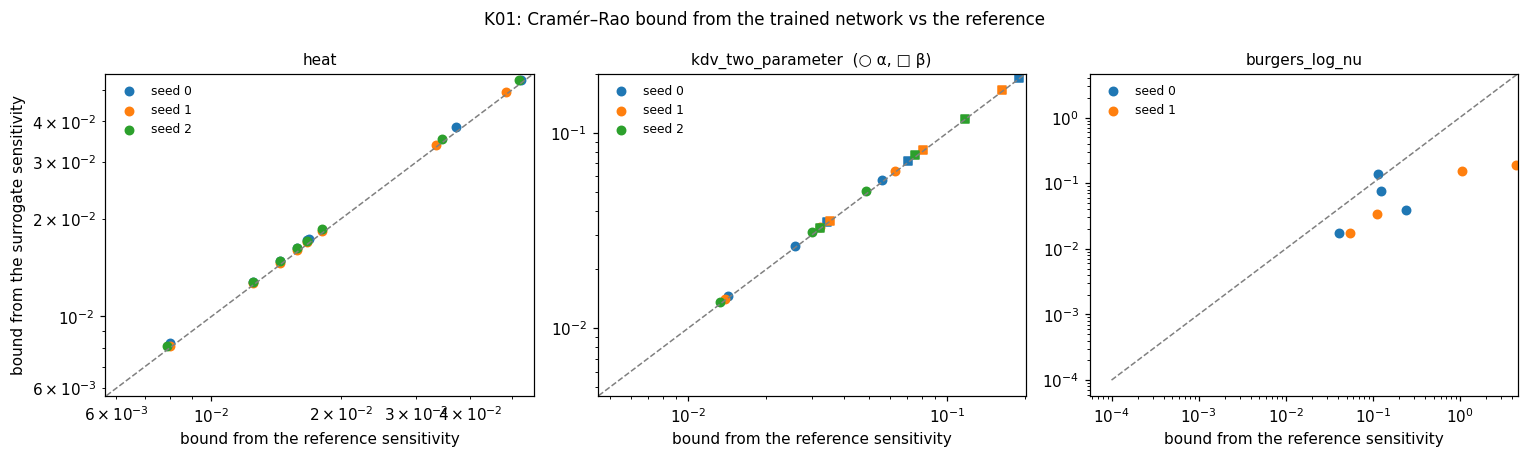

**Conclusion (from `experiments/K01_fisher_information/README.md`)**


_Pending._


In [6]:
if runs:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
    for ax, problem in zip(axes, ["heat", "kdv_two_parameter", "burgers_log_nu"]):
        for rec in [r for r in runs if r["problem"] == problem]:
            for c in rec["cells"]:
                for k in c["exact"]["rel_std"]:
                    ax.scatter(c["exact"]["rel_std"][k], c["surrogate"]["rel_std"][k], s=30, color=f"C{rec['seed']}",
                               marker="o" if k in ("alpha", "log_nu") else "s", label=f"seed {rec['seed']}" if c is rec["cells"][0] and k in ("alpha", "log_nu") else None)
        lo = min(ax.get_xlim()[0], ax.get_ylim()[0]); hi = max(ax.get_xlim()[1], ax.get_ylim()[1])
        ax.plot([1e-4, 10], [1e-4, 10], "--", color="gray", linewidth=1)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.set_title(problem + ("  (○ α, □ β)" if problem.startswith("kdv") else ""), fontsize=10)
        ax.set_xlabel("bound from the reference sensitivity"); ax.legend(frameon=False, fontsize=8)
    axes[0].set_ylabel("bound from the surrogate sensitivity")
    plt.suptitle("K01: Cramér–Rao bound from the trained network vs the reference", fontsize=11)
    plt.tight_layout(); plt.show()
    readme("K01_fisher_information")

## K03: is PINN training ill-conditioned by the differential operator?

**Setup.** Eight catalogue problems spanning operator orders (first-order convection; second-order heat, wave, Klein–Gordon, Poisson; nonlinear Burgers travelling wave and Allen–Cahn; the fourth-order beam) × two architectures (tanh MLP, Fourier features), two seeds, 3,000 Adam steps. For each: the extreme Ritz values of the physics-loss Hessian, the tangent-kernel traces and condition numbers of the residual, boundary and initial terms on 96 points, and the relative L2 error where a closed form exists.

In [7]:
runs = load("K03_training_conditioning")
if runs:
    rows = []
    for rec in sorted(runs, key=lambda r: (r["problem"], r["arch"], r["seed"])):
        h, k = rec["hessian"], rec["kernels"]
        ratio = k["residual"]["trace"] / k["boundary"]["trace"] if "boundary" in k and k["boundary"]["trace"] else float("nan")
        rows.append([rec["problem"], rec["arch"], rec["seed"], "–" if rec["l2_error"] is None else f"{rec['l2_error']:.3f}", f"{rec['final_loss']:.2e}",
                     f"{h['largest']:.3g}", f"{h['smallest']:.3g}", f"{h['condition_number']:.3g}", f"{ratio:.3g}", f"{k['residual']['condition_number']:.3g}"])
    table(["problem", "arch", "seed", "rel. L2", "final loss", "H: λ_max", "H: λ_min", "κ(H⁺)", "tr(K_res) / tr(K_bc)", "κ(K_res)"], rows)

> **K03_training_conditioning has no results yet.** Run `python experiments/K03_training_conditioning/run.py` first.

In [8]:
if runs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    for rec in runs:
        if rec["l2_error"] is None:
            continue
        m = "o" if rec["arch"] == "feedforward" else "^"
        axes[0].scatter(rec["hessian"]["largest"], rec["l2_error"], marker=m, s=40, color="#2a78d6")
        axes[0].annotate(rec["problem"], (rec["hessian"]["largest"], rec["l2_error"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
        k = rec["kernels"]
        ratio = k["residual"]["trace"] / k["boundary"]["trace"]
        axes[1].scatter(ratio, rec["l2_error"], marker=m, s=40, color="#eb6834")
        axes[1].annotate(rec["problem"], (ratio, rec["l2_error"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
    for ax, xl in zip(axes, ["largest Hessian eigenvalue (○ MLP, △ Fourier)", "tr(K_residual) / tr(K_boundary)"]):
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(xl); ax.set_ylabel("relative L2 error after 3,000 steps")
    plt.suptitle("K03: training conditioning against final error", fontsize=11)
    plt.tight_layout(); plt.show()
    readme("K03_training_conditioning")

## What to take from the two experiments

- The surrogate's Fisher information is trustworthy **when the surrogate resolves the solution**: on heat and the KdV soliton it reproduces the bound, the correlation and the condition number from the reference to a few percent. On the Burgers shock, which the network smooths, it is off by an order of magnitude and in the optimistic direction. The field error reported next to every surrogate bound is the condition to check first.
- Training conditioning is a property of the **operator and the architecture**, not of the data; the Hessian's largest eigenvalue and the kernel trace ratios say which problems need a smaller learning rate, loss re-weighting or a different architecture before any identification is attempted.